### Environment & Capstone Dataset Generation

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, roc_curve

sns.set_theme(style="whitegrid")
%matplotlib inline

np.random.seed(42)
n = 1500

contract_types = ['Month-to-Month', 'One-Year', 'Two-Year']
internet_services = ['Fiber Optic', 'DSL', 'No']
payment_methods = ['Electronic Check', 'Mailed Check', 'Bank Transfer', 'Credit Card']

tenure = np.random.randint(1, 73, size=n)
contract = np.random.choice(contract_types, size=n, p=[0.55, 0.25, 0.20])
internet = np.random.choice(internet_services, size=n, p=[0.45, 0.35, 0.20])
payment = np.random.choice(payment_methods, size=n, p=[0.35, 0.25, 0.20, 0.20])
senior_citizen = np.random.choice([0, 1], size=n, p=[0.84, 0.16])
partner = np.random.choice([0, 1], size=n, p=[0.52, 0.48])
dependents = np.random.choice([0, 1], size=n, p=[0.70, 0.30])
tech_support = np.random.choice([0, 1], size=n, p=[0.70, 0.30])

monthly_charges = []
for i in range(n):
    base = 20.0
    if internet[i] == 'Fiber Optic':
        base += 50.0 + np.random.uniform(5, 25)
    elif internet[i] == 'DSL':
        base += 25.0 + np.random.uniform(5, 15)
    else:
        base += np.random.uniform(0, 10)
    if tech_support[i] == 1:
        base += 10.0
    monthly_charges.append(round(base, 2))
monthly_charges = np.array(monthly_charges)

total_charges = (monthly_charges * tenure + np.random.normal(0, 20, size=n)).round(2)
total_charges = np.maximum(total_charges, monthly_charges)

# Realistic churn logic driven by tenure, contract type, and service tiers
churn_risk = (
    0.20
    - (tenure / 72.0) * 0.35
    + (monthly_charges / 120.0) * 0.25
    + (contract == 'Month-to-Month') * 0.30
    - (contract == 'Two-Year') * 0.25
    + (internet == 'Fiber Optic') * 0.15
    - (tech_support == 1) * 0.15
    + (senior_citizen == 1) * 0.08
)
churn_risk = np.clip(churn_risk, 0.03, 0.95)
churn = (np.random.rand(n) < churn_risk).astype(int)

df = pd.DataFrame({
    'SeniorCitizen': senior_citizen,
    'Partner': partner,
    'Dependents': dependents,
    'Tenure': tenure,
    'Contract': contract,
    'InternetService': internet,
    'TechSupport': tech_support,
    'PaymentMethod': payment,
    'MonthlyCharges': monthly_charges,
    'TotalCharges': total_charges,
    'Churn': churn
})

# Feature engineering
df['TotalServices'] = (df['InternetService'] != 'No').astype(int) + df['TechSupport'] + df['Partner'] + df['Dependents']
df['ChargesPerTenure'] = (df['TotalCharges'] / (df['Tenure'] + 1)).round(2)

print(f"Dataset Shape: {df.shape}")
df.head()

Dataset Shape: (1500, 13)


,SeniorCitizen,Partner,Dependents,Tenure,Contract,InternetService,TechSupport,PaymentMethod,MonthlyCharges,TotalCharges,Churn,TotalServices,ChargesPerTenure
0,0,0,0,52,Two-Year,DSL,1,Bank Transfer,64.36,3315.52,0,2,62.56
1,0,1,0,15,Month-to-Month,Fiber Optic,0,Mailed Check,90.80,1404.35,0,2,87.77
2,0,0,1,72,Two-Year,Fiber Optic,0,Credit Card,91.36,6569.69,0,2,90.00
3,0,0,0,61,Month-to-Month,No,0,Credit Card,22.90,1399.81,1,0,22.58
4,0,0,0,21,Month-to-Month,DSL,0,Electronic Check,53.40,1083.56,0,1,49.25


### Exploratory Diagnostics & Correlation Matrix

In [2]:
print("--- Schema Diagnostics ---")
print(df.info())

num_cols = ['SeniorCitizen', 'Partner', 'Dependents', 'Tenure', 'TechSupport', 'MonthlyCharges', 'TotalCharges', 'TotalServices', 'ChargesPerTenure', 'Churn']
corr_matrix = df[num_cols].corr().round(4)

print("\n--- Pearson Correlation Matrix ---")
print(corr_matrix)

--- Schema Diagnostics ---
<class 'pandas.DataFrame'>
RangeIndex: 1500 entries, 0 to 1499
Data columns (total 13 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   SeniorCitizen     1500 non-null   int64  
 1   Partner           1500 non-null   int64  
 2   Dependents        1500 non-null   int64  
 3   Tenure            1500 non-null   int32  
 4   Contract          1500 non-null   str    
 5   InternetService   1500 non-null   str    
 6   TechSupport       1500 non-null   int64  
 7   PaymentMethod     1500 non-null   str    
 8   MonthlyCharges    1500 non-null   float64
 9   TotalCharges      1500 non-null   float64
 10  Churn             1500 non-null   int64  
 11  TotalServices     1500 non-null   int64  
 12  ChargesPerTenure  1500 non-null   float64
dtypes: float64(3), int32(1), int64(6), str(3)
memory usage: 192.4 KB
None

--- Pearson Correlation Matrix ---
                  SeniorCitizen  Partner  Dependents  Tenure 

### Machine Learning Benchmark & ROC Curve Analysis

In [3]:
X_encoded = pd.get_dummies(df.drop(columns=['Churn']), drop_first=True)
y = df['Churn']

X_train, X_test, y_train, y_test = train_test_split(X_encoded, y, test_size=0.20, random_state=42, stratify=y)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

models = {
    'Logistic Regression': LogisticRegression(random_state=42, max_iter=500),
    'Random Forest': RandomForestClassifier(n_estimators=150, max_depth=8, random_state=42),
    'Gradient Boosting': GradientBoostingClassifier(n_estimators=120, learning_rate=0.08, max_depth=4, random_state=42)
}

results = []
roc_curves = {}

for name, m in models.items():
    m.fit(X_train_scaled, y_train)
    preds = m.predict(X_test_scaled)
    probs = m.predict_proba(X_test_scaled)[:, 1]
    
    acc = accuracy_score(y_test, preds)
    prec = precision_score(y_test, preds)
    rec = recall_score(y_test, preds)
    f1 = f1_score(y_test, preds)
    auc = roc_auc_score(y_test, probs)
    
    fpr, tpr, _ = roc_curve(y_test, probs)
    roc_curves[name] = (fpr, tpr, auc)
    
    results.append({
        'Model': name,
        'Accuracy': f"{acc*100:.2f}%",
        'Precision': f"{prec*100:.2f}%",
        'Recall': f"{rec*100:.2f}%",
        'F1_Score': f"{f1*100:.2f}%",
        'ROC_AUC': f"{auc:.4f}"
    })

benchmark_df = pd.DataFrame(results)
print("--- Algorithmic Benchmarks ---")
print(benchmark_df)

--- Algorithmic Benchmarks ---
                 Model Accuracy Precision  Recall F1_Score ROC_AUC
0  Logistic Regression   71.67%    60.00%  47.52%   53.04%  0.7770
1        Random Forest   71.33%    60.27%  43.56%   50.57%  0.7547
2    Gradient Boosting   70.67%    58.67%  43.56%   50.00%  0.7366


### 4-Panel Capstone Visual Dashboard

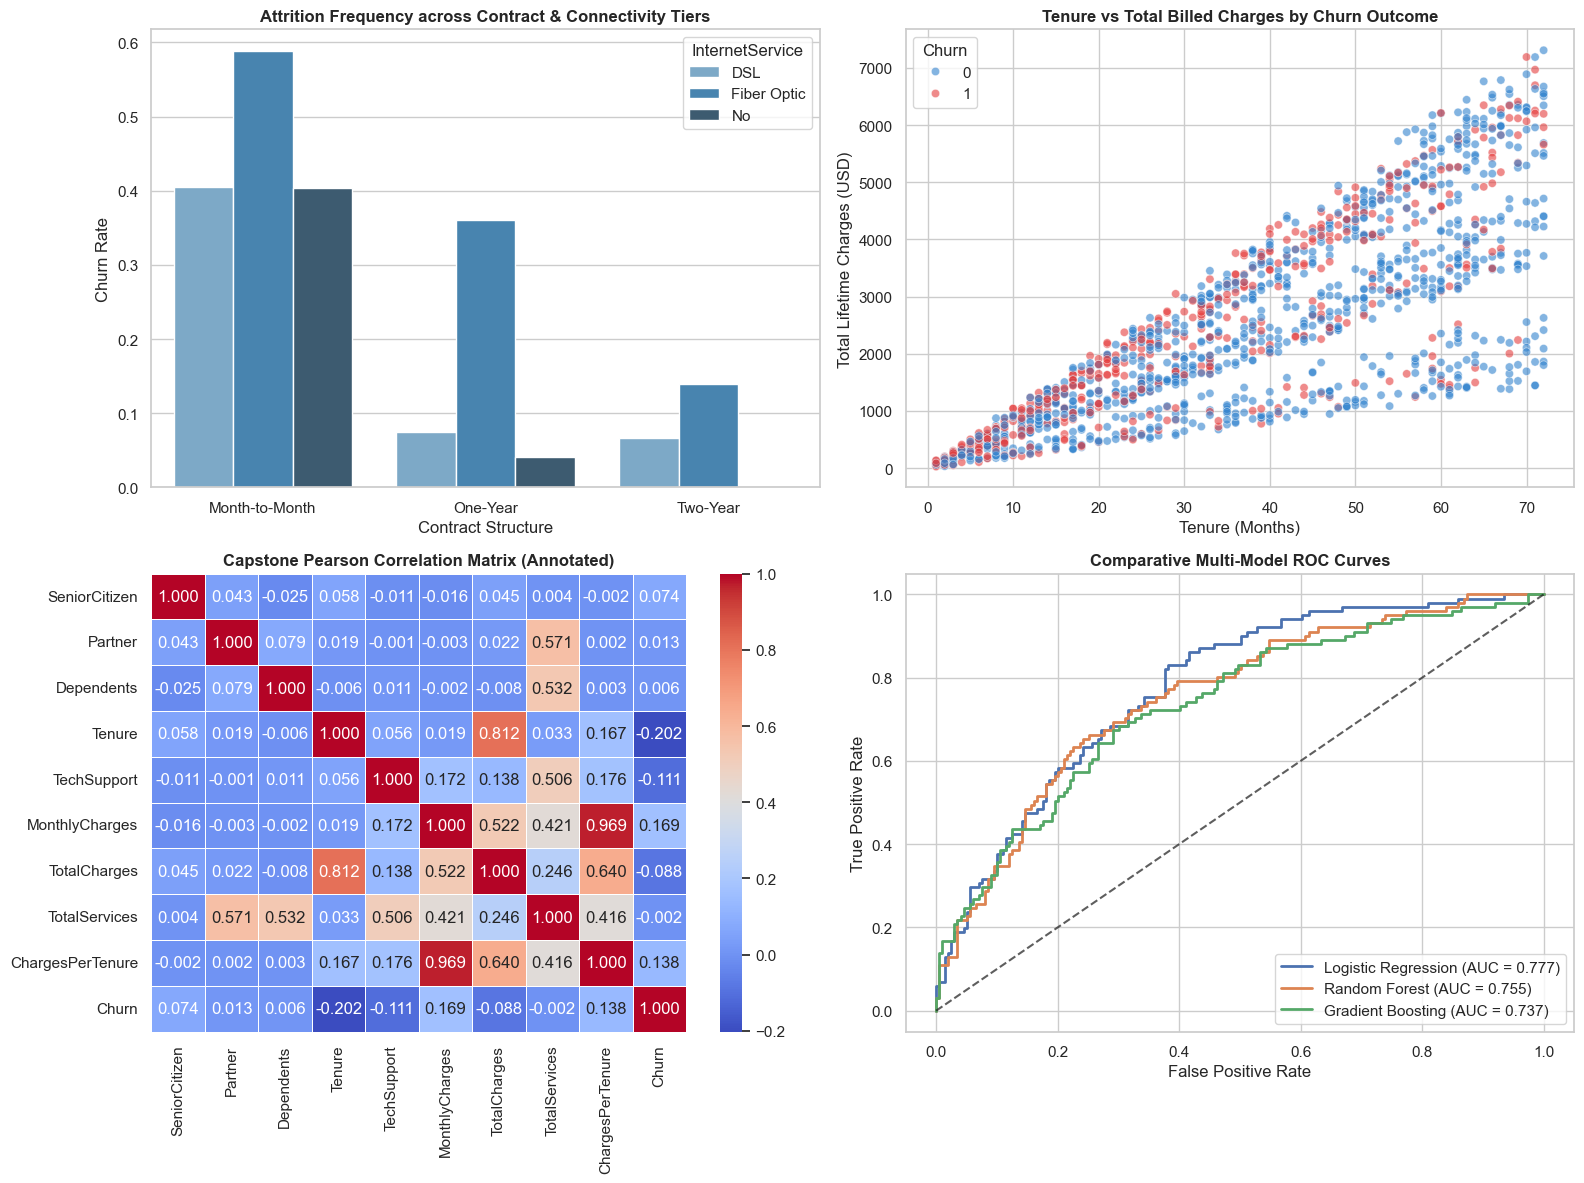

In [4]:
fig, axes = plt.subplots(2, 2, figsize=(16, 12))

# 1. Churn by Contract Type & Internet Service
contract_churn = df.groupby(['Contract', 'InternetService'], observed=True)['Churn'].mean().reset_index()
sns.barplot(
    data=contract_churn,
    x='Contract',
    y='Churn',
    hue='InternetService',
    palette='Blues_d',
    ax=axes[0, 0]
)
axes[0, 0].set_title('Attrition Frequency across Contract & Connectivity Tiers', fontsize=12, fontweight='bold')
axes[0, 0].set_ylabel('Churn Rate')
axes[0, 0].set_xlabel('Contract Structure')

# 2. Tenure vs Total Charges Hex/Scatter by Churn
sns.scatterplot(
    data=df,
    x='Tenure',
    y='TotalCharges',
    hue='Churn',
    palette=['#3182CE', '#E53E3E'],
    alpha=0.6,
    ax=axes[0, 1]
)
axes[0, 1].set_title('Tenure vs Total Billed Charges by Churn Outcome', fontsize=12, fontweight='bold')
axes[0, 1].set_ylabel('Total Lifetime Charges (USD)')
axes[0, 1].set_xlabel('Tenure (Months)')

# 3. Annotated Correlation Heatmap
sns.heatmap(corr_matrix, annot=True, fmt='.3f', cmap='coolwarm', ax=axes[1, 0], cbar=True, linewidths=0.5)
axes[1, 0].set_title('Capstone Pearson Correlation Matrix (Annotated)', fontsize=12, fontweight='bold')

# 4. Multi-Model ROC Curves
for name, (fpr, tpr, auc_val) in roc_curves.items():
    axes[1, 1].plot(fpr, tpr, label=f"{name} (AUC = {auc_val:.3f})", lw=2)
axes[1, 1].plot([0, 1], [0, 1], 'k--', lw=1.5, alpha=0.7)
axes[1, 1].set_title('Comparative Multi-Model ROC Curves', fontsize=12, fontweight='bold')
axes[1, 1].set_xlabel('False Positive Rate')
axes[1, 1].set_ylabel('True Positive Rate')
axes[1, 1].legend(loc='lower right')

plt.tight_layout()
plt.savefig('task6_capstone_visuals.png', dpi=300)
plt.show()